# 02 — Limpieza y preparación de datos

**Proyecto:** Análisis de Elasticidad de Demanda en Delivery de Comida (v2)
**Fase:** 2 — Limpieza y preparación

Objetivos de este notebook:
1. Ejecutar el pipeline de carga y unión de datos (`src/data_prep.py`)
2. Construir las variables de variación de precio y sus versiones logarítmicas
3. Verificar la consistencia de las variables de precio (casos donde el precio final supera al precio de referencia)
4. Guardar el dataset procesado en `data/processed/`


In [1]:
import sys
sys.path.append('../src')

from data_prep import pipeline_completo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

## 1. Ejecutar el pipeline de preparación

In [2]:
df = pipeline_completo('../data/raw')
df.shape

(456548, 20)

## 2. Verificación de las variables de precio

In [3]:
df[['base_price', 'checkout_price', 'variacion_precio', 'variacion_precio_pct',
    'log_checkout_price', 'num_orders', 'log_num_orders']].describe()

,base_price,checkout_price,variacion_precio,variacion_precio_pct,log_checkout_price,num_orders,log_num_orders
count,456548.000000,456548.000000,456548.000000,456548.000000,456548.000000,456548.000000,456548.000000
mean,354.156627,332.238933,21.917695,5.719500,5.695404,261.872760,4.888190
std,160.715914,152.939723,48.495857,11.362753,0.482938,395.922798,1.203166
min,55.350000,2.970000,-185.300000,-72.789753,1.088562,13.000000,2.639057
25%,243.500000,228.950000,-1.000000,-0.145406,5.433504,54.000000,4.007333
50%,310.460000,296.820000,1.000000,0.141217,5.693126,136.000000,4.919981
75%,458.870000,445.230000,16.520000,6.242147,6.098591,324.000000,5.783825
max,866.270000,866.270000,561.600000,99.060870,6.764197,24299.000000,10.098232


## 3. Casos donde el precio final superó al precio de referencia

`base_price` no es necesariamente un piso: en una parte de las observaciones,
`checkout_price` es mayor a `base_price`, lo que produce `variacion_precio` negativa.

In [4]:
variaciones_negativas = df[df['variacion_precio'] < 0]
print(f"Filas con aumento de precio: {len(variaciones_negativas)} "
      f"({len(variaciones_negativas)/len(df)*100:.2f}%)")
variaciones_negativas[['base_price', 'checkout_price', 'variacion_precio']].head(10)

Filas con aumento de precio: 116101 (25.43%)


,base_price,checkout_price,variacion_precio
1,135.83,136.83,-1.0
4,242.50,243.50,-1.0
8,192.06,193.06,-1.0
12,310.43,311.43,-1.0
15,281.33,282.33,-1.0
17,485.00,486.00,-1.0
18,305.58,306.58,-1.0
27,627.62,628.62,-1.0
28,626.62,627.62,-1.0
29,626.62,628.62,-2.0


### 3.1 Distribución de los montos de aumento

In [5]:
variaciones_negativas['variacion_precio'].describe()

count    116101.000000
mean         -1.854677
std           4.565274
min        -185.300000
25%          -2.000000
50%          -1.000000
75%          -1.000000
max          -0.030000
Name: variacion_precio, dtype: float64

### 3.2 Verificación por centro (¿el patrón está concentrado o distribuido?)

In [6]:
variaciones_negativas.groupby('center_id').size().sort_values(ascending=False).head(10)

center_id
108    1907
10     1840
43     1778
52     1768
59     1760
27     1753
137    1752
174    1752
13     1741
51     1731
dtype: int64

**Hallazgo documentado en `reports/bitacora_metodologica.md`:** los montos son
variados (no un cargo fijo pequeño) y la incidencia está repartida de forma
pareja entre centros. Se interpreta como que `base_price` es un precio de
referencia/lista, no un piso garantizado — no es un error de datos.

**Decisión:** se conservan todas las observaciones. Se usa `hubo_aumento`
como variable de control candidata para el modelo de la Fase 3.

## 4. Variable `hubo_aumento`

In [7]:
df['hubo_aumento'].value_counts(normalize=True).rename('proporcion')

hubo_aumento
0    0.745698
1    0.254302
Name: proporcion, dtype: float64

## 5. Distribución de las variables transformadas

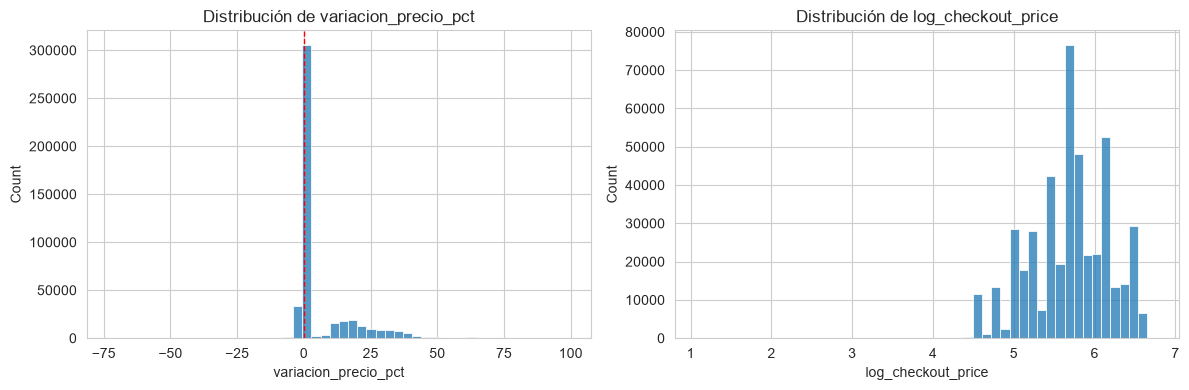

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['variacion_precio_pct'], bins=50, ax=axes[0])
axes[0].axvline(0, color='red', linestyle='--', linewidth=1)
axes[0].set_title('Distribución de variacion_precio_pct')

sns.histplot(df['log_checkout_price'], bins=50, ax=axes[1])
axes[1].set_title('Distribución de log_checkout_price')

plt.tight_layout()
plt.show()

## 6. Guardar dataset procesado

In [9]:
df.to_csv('../data/processed/demanda_limpia.csv', index=False)
print(f'Guardado: {df.shape[0]} filas, {df.shape[1]} columnas')

Guardado: 456548 filas, 20 columnas


## Próximos pasos (Fase 3 — modelado de elasticidad)
- Modelo base log-log: `log_num_orders ~ log_checkout_price`
- Modelo con controles: agregar `emailer_for_promotion`, `homepage_featured`, `hubo_aumento`, efectos por centro/comida
- Especificación alternativa semi-log para comparar
- Selección de modelo con AIC/BIC